# inD Dataset – Data Understanding

The **inD** (intersection Drone) dataset was recorded at four urban intersections in Aachen, Germany by RWTH Aachen University (IKA) using drone footage. It captures naturalistic trajectories of road users at signalised and unsignalised intersections.

Each recording comes with three CSV files:
- `XX_recordingMeta.csv` – recording-level metadata (location, duration, counts)
- `XX_tracksMeta.csv` – one row per tracked object (class, size)
- `XX_tracks.csv` – per-frame positions, velocities, and accelerations

This notebook explores the dataset at a high level before any modelling.

In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "inD-dataset-v1.1/data"

recording_meta = pd.concat(
    [pd.read_csv(f) for f in sorted(glob.glob(f"{DATA_DIR}/*_recordingMeta.csv"))],
    ignore_index=True,
)

tracks_meta = pd.concat(
    [pd.read_csv(f) for f in sorted(glob.glob(f"{DATA_DIR}/*_tracksMeta.csv"))],
    ignore_index=True,
)

## Basic Dataset Facts

In [2]:
n_recordings     = len(recording_meta)
n_locations      = recording_meta["locationId"].nunique()
total_duration_h = recording_meta["duration"].sum() / 3600
total_tracks     = recording_meta["numTracks"].sum()
total_vehicles   = recording_meta["numVehicles"].sum()
total_vrus       = recording_meta["numVRUs"].sum()

print(f"Recordings      : {n_recordings}")
print(f"Locations       : {n_locations}")
print(f"Total duration  : {total_duration_h:.1f} h")
print(f"Tracked objects : {total_tracks:,}  (vehicles: {total_vehicles:,}, VRUs: {total_vrus:,})")
print(f"Frame rate      : {recording_meta['frameRate'].unique()} Hz")
print(f"Speed limit     : {sorted(recording_meta['speedLimit'].unique() * 3.6)} km/h")

Recordings      : 33
Locations       : 4
Total duration  : 9.8 h
Tracked objects : 13,599  (vehicles: 8,233, VRUs: 5,366)
Frame rate      : [25.] Hz
Speed limit     : [np.float64(50.000004000000004)] km/h


## Recordings per Location

In [3]:
per_location = recording_meta.groupby("locationId").agg(
    recordings=("recordingId", "count"),
    total_duration_min=("duration", lambda s: s.sum() / 60),
    total_tracks=("numTracks", "sum"),
    total_vehicles=("numVehicles", "sum"),
    total_vrus=("numVRUs", "sum"),
)
per_location

,recordings,total_duration_min,total_tracks,total_vehicles,total_vrus
locationId,,,,,
1,11,185.350667,3738,2503,1235
2,12,242.560667,6235,2436,3799
3,3,51.063333,1279,1196,83
4,7,110.179333,2347,2098,249


## Object Class Distribution

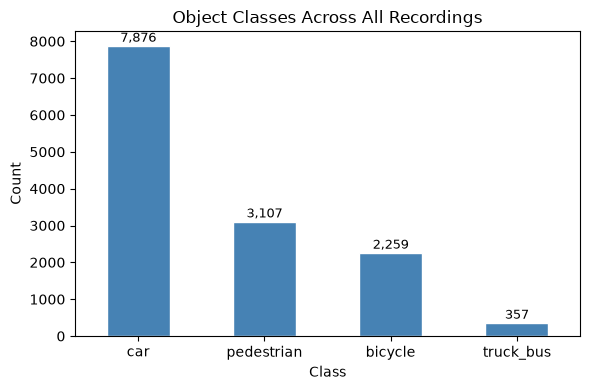

class
car           7876
pedestrian    3107
bicycle       2259
truck_bus      357


In [ ]:
class_counts = tracks_meta["class"].value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Object Classes Across All Recordings")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=0)
for bar, count in zip(ax.patches, class_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            f"{count:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()